# Optical Flow Neural Network

In [4]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

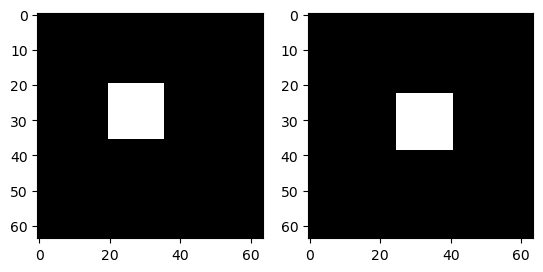

In [5]:
def generate_pair(size=64, shift_x=5, shift_y=3):
    img1 = np.zeros((size, size), dtype=np.float32)
    img2 = np.zeros_like(img1)

    x, y = 20, 20
    s = 16

    img1[y:y+s, x:x+s] = 1.0
    img2[y+shift_y:y+s+shift_y,
         x+shift_x:x+s+shift_x] = 1.0

    return img1, img2

img1, img2 = generate_pair()

fig, axes = plt.subplots(1, 2)
axes[0].imshow(img1, cmap="gray")
axes[1].imshow(img2, cmap="gray")
plt.show()

In [6]:
class MotionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(2, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.model(x)

In [7]:
class SquareMotionDataset(Dataset):
    def __init__(self, n_samples=10000, size=64, max_shift=8):
        self.n_samples = n_samples
        self.size = size
        self.max_shift = max_shift

    def __len__(self):
        return self.n_samples

    def __getitem__(self, idx):
        size = self.size
        square_size = 16
        m = self.max_shift

        # Random starting position, with room for movement
        x = np.random.randint(m, size - square_size - m + 1)
        y = np.random.randint(m, size - square_size - m + 1)

        dx = np.random.randint(-m, m + 1)
        dy = np.random.randint(-m, m + 1)

        img1 = np.zeros((size, size), dtype=np.float32)
        img2 = np.zeros((size, size), dtype=np.float32)

        img1[y:y+square_size, x:x+square_size] = 1.0
        img2[y+dy:y+dy+square_size,
             x+dx:x+dx+square_size] = 1.0

        images = np.stack([img1, img2], axis=0)
        displacement = np.array([dx, dy], dtype=np.float32)

        return (
            torch.from_numpy(images),
            torch.from_numpy(displacement)
        )


In [8]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Device:", device)

train_dataset = SquareMotionDataset(n_samples=10000)
val_dataset = SquareMotionDataset(n_samples=2000)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False
)

Device: mps


In [9]:
model = MotionCNN().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 20
train_losses = []
val_losses = []

In [10]:
for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        predictions = model(images)
        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_dataset)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            predictions = model(images)
            loss = criterion(predictions, targets)

            running_val_loss += loss.item() * images.size(0)

    val_loss = running_val_loss / len(val_dataset)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )


Epoch 01/20 | Train Loss: 5.1494 | Val Loss: 0.3235
Epoch 02/20 | Train Loss: 0.2086 | Val Loss: 0.1617
Epoch 03/20 | Train Loss: 0.1207 | Val Loss: 0.1427
Epoch 04/20 | Train Loss: 0.0677 | Val Loss: 0.0684
Epoch 05/20 | Train Loss: 0.0403 | Val Loss: 0.0416
Epoch 06/20 | Train Loss: 0.0386 | Val Loss: 0.0355
Epoch 07/20 | Train Loss: 0.0321 | Val Loss: 0.0263
Epoch 08/20 | Train Loss: 0.0267 | Val Loss: 0.0292
Epoch 09/20 | Train Loss: 0.0220 | Val Loss: 0.0260
Epoch 10/20 | Train Loss: 0.0224 | Val Loss: 0.0137
Epoch 11/20 | Train Loss: 0.0220 | Val Loss: 0.0226
Epoch 12/20 | Train Loss: 0.0255 | Val Loss: 0.0171
Epoch 13/20 | Train Loss: 0.0153 | Val Loss: 0.0288
Epoch 14/20 | Train Loss: 0.0192 | Val Loss: 0.0174
Epoch 15/20 | Train Loss: 0.0184 | Val Loss: 0.0680
Epoch 16/20 | Train Loss: 0.0186 | Val Loss: 0.0185
Epoch 17/20 | Train Loss: 0.0116 | Val Loss: 0.0088
Epoch 18/20 | Train Loss: 0.0116 | Val Loss: 0.0162
Epoch 19/20 | Train Loss: 0.0129 | Val Loss: 0.0186
Epoch 20/20 

In [11]:
torch.save(model.state_dict(), "motion_cnn.pth")

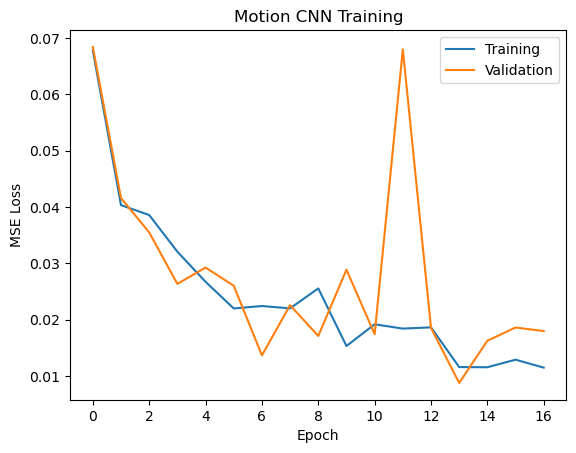

In [13]:
plt.plot(train_losses[3:], label="Training")
plt.plot(val_losses[3:], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Motion CNN Training")
plt.legend()
plt.show()


True displacement: [1. 2.]
Predicted displacement: [0.8724016 1.9083171]


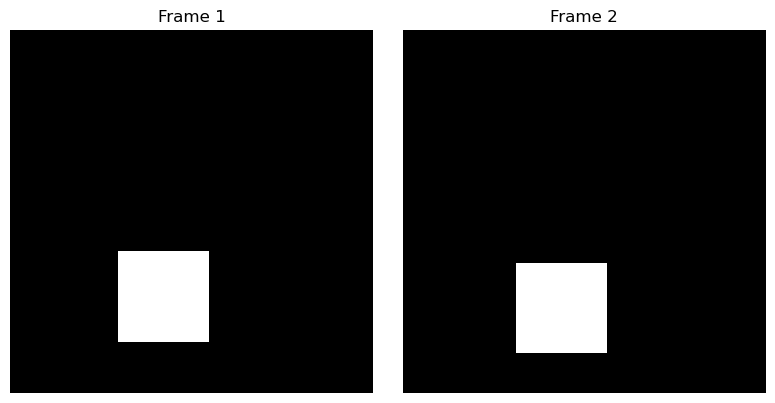

In [15]:
model.eval()

test_images, true_flow = val_dataset[0]

with torch.no_grad():
    predicted_flow = model(
        test_images.unsqueeze(0).to(device)
    ).cpu().squeeze(0)

print("True displacement:", true_flow.numpy())
print("Predicted displacement:", predicted_flow.numpy())

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(test_images[0], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Frame 1")

axes[1].imshow(test_images[1], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Frame 2")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


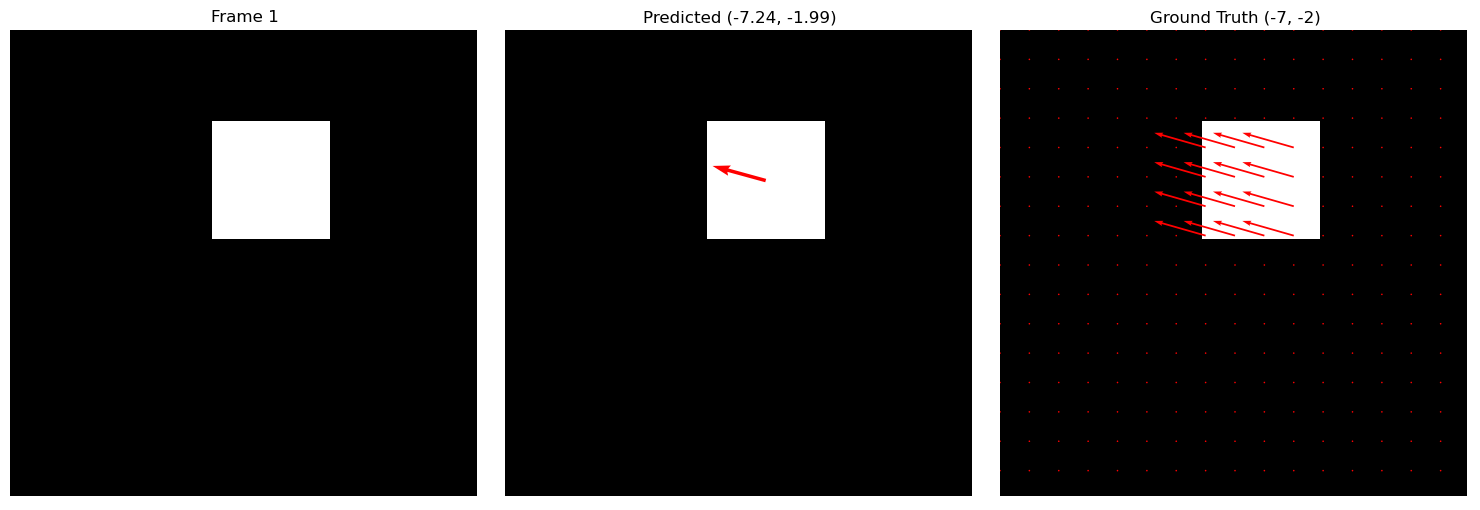

True: [-7. -2.]
Predicted: [-7.243816 -1.989333]


In [26]:

# ===== VISUALIZATION =====

import numpy as np
import matplotlib.pyplot as plt

model.eval()

# Get sample
images, true_flow = val_dataset[0]

# Move inputs to the correct device for inference
input_images = images.unsqueeze(0).to(device)

with torch.no_grad():
    prediction = model(input_images)

# Convert EVERYTHING to CPU NumPy arrays
images_np = images.detach().cpu().numpy()
true_flow_np = true_flow.detach().cpu().numpy()
prediction_np = prediction.detach().cpu().numpy()[0]

img1 = images_np[0]
img2 = images_np[1]

true_dx = float(true_flow_np[0])
true_dy = float(true_flow_np[1])

pred_dx = float(prediction_np[0])
pred_dy = float(prediction_np[1])

# Find square center
ys, xs = np.where(img1 > 0.5)
cx = float(xs.mean())
cy = float(ys.mean())

# Create dense ground-truth flow
H, W = img1.shape
flow = np.zeros((H, W, 2), dtype=np.float32)

mask = img1 > 0.5
flow[mask, 0] = true_dx
flow[mask, 1] = true_dy

# Create plot
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img1, cmap="gray")
axes[0].set_title("Frame 1")

axes[1].imshow(img1, cmap="gray")
axes[1].quiver(
    [cx], [cy], [pred_dx], [pred_dy],
    color="red",
    angles="xy",
    scale_units="xy",
    scale=1
)
axes[1].set_title(
    f"Predicted ({pred_dx:.2f}, {pred_dy:.2f})"
)

step = 4
Y, X = np.mgrid[0:H:step, 0:W:step]

U = flow[::step, ::step, 0]
V = flow[::step, ::step, 1]

axes[2].imshow(img1, cmap="gray")
axes[2].quiver(
    X, Y, U, V,
    color="red",
    angles="xy",
    scale_units="xy",
    scale=1
)
axes[2].set_title(
    f"Ground Truth ({true_dx:.0f}, {true_dy:.0f})"
)

for ax in axes:
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("True:", true_flow_np)
print("Predicted:", prediction_np)
